# Solutions to the exercises of Chapter 16

Sample solutions for [Chapter 16, Convective mass transfer](../../notebooks/part4_mass_transfer/16_convective_mass_transfer.ipynb).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

try:
    from engtransport import convective_mass, phase_change, properties, reference
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import convective_mass, phase_change, properties, reference
from engtransport.numerics import bisect
from engtransport.plotting import panel_label, use_style

use_style()
M_WATER, R_GAS, P_ATM = 0.018015, 8.314462618, 101325.0

## Exercise 1. A solvent spill

The pool is a flat plate 1 m long at $Re = UL/\nu$; the evaporation rate follows from
Eqs. (16.3), (16.7) and (16.8) as in Section 16.4. For the extraction, the acetone leaves
at a molar rate $\dot n = \dot m''A/M$; to keep its mole fraction in the extract at
$x \le 0.025$, the extract must carry at least $\dot n(1 - x)/x$ of air, whose volume at
20 °C and 1 atm is $RT/P$ per mole.

In [2]:
T, U, L, A, V_liq = 293.15, 0.5, 1.0, 1.0, 1e-3
air = properties.dry_air_properties(T)
sat = properties.solvent_saturation("acetone", T)
D = properties.fuller_diffusivity("C3H6O", "Air", T)
Sc, Re = air["nu"] / D, U * L / air["nu"]
m_s = convective_mass.vapour_mass_fraction(sat["p_sat"], sat["M"])
B = convective_mass.spalding_number(m_s, 0.0)
g_star = air["rho"] * D * convective_mass.sherwood_flat_plate(Re, Sc) / L
ratio = reference.species_similarity(Sc, B)["dphi0"] / reference.species_similarity(Sc)["dphi0"]
fluxes = {"low rate (16.1)": g_star * m_s, "film model (16.7)": g_star * math.log1p(B), "boundary layer (16.8)": g_star * B * ratio}
mass = sat["rho_l"] * V_liq
print(f"Re = {Re:.3g}, Sc = {Sc:.2f}, p_sat = {sat['p_sat'] / 1e3:.1f} kPa, m_s = {m_s:.3f}, B = {B:.3f}; spilled {mass:.3f} kg")
for label, f in fluxes.items():
    print(f"{label:22s}: {1e3 * f:.2f} g/(m2 s), pool gone in {mass / (f * A) / 60:.1f} min")
n_dot = fluxes["boundary layer (16.8)"] * A / sat["M"]
x_lel = 0.025
Q = n_dot * (1 - x_lel) / x_lel * R_GAS * T / P_ATM
print(f"acetone {1e3 * n_dot:.2f} mmol/s; extraction at least {60 * Q:.1f} m3/min ({3600 * Q:.0f} m3/h)")

Re = 3.31e+04, Sc = 1.47, p_sat = 24.7 kPa, m_s = 0.392, B = 0.645; spilled 0.790 kg
low rate (16.1)       : 0.67 g/(m2 s), pool gone in 19.7 min
film model (16.7)     : 0.85 g/(m2 s), pool gone in 15.6 min
boundary layer (16.8) : 0.77 g/(m2 s), pool gone in 17.1 min
acetone 13.24 mmol/s; extraction at least 0.7 m3/min (45 m3/h)


The flow is laminar ($Re = 3.3\times10^4$), and acetone at 20 °C has $B = 0.65$. The pool
evaporates at 0.77 g/(m² s) by the boundary layer, so the litre (0.79 kg) is gone in 17
minutes; the low-rate formula gives 20 minutes and the film model 16. The extraction must
carry at least 0.7 m³ of air a minute (45 m³/h) if the vapour is to stay below the lower
explosive limit on average. That is a small fan, but the average hides the danger: acetone vapour is
twice as dense as air and collects near the floor at concentrations far above the average,
which is why spills are ventilated from low down. In practice the pool also cools, since the
floor cannot supply the latent heat as fast as the liquid evaporates, so the true time is
longer (an energy balance of the kind in Chapter 17).

## Exercise 2. The wetted-wall column

The ratio of the two formulas is $Re^{0.03}Sc^{0.107}$. Along the tube, the bulk vapour
fraction rises as the air takes up vapour: with $\dot m_{air}\,dm = g^*\pi D(m_s - m)\,dx$
and $\dot m_{air} = \rho u\pi D^2/4$, the approach to saturation is
$(m_s - m)/m_s = \exp[-4\,Sh\,x/(Re\,Sc\,D)]$, so 90 % saturation needs
$x = \ln 10\,Re\,Sc\,D/(4\,Sh)$. For water at 25 °C, $B = 0.02$ and blowing is ignored.

In [3]:
T = 298.15
air = properties.dry_air_properties(T)
vapours = {"water": properties.water_vapour_diffusivity_air(T), "ethanol": properties.fuller_diffusivity("C2H5OH", "Air", T),
           "diethyl ether": properties.fuller_diffusivity("C4H10O", "Air", T)}
Sh_gs = lambda Re, Sc: 0.023 * Re**0.83 * Sc**0.44
Sh_cc = lambda Re, Sc: 0.023 * Re**0.8 * Sc ** (1 / 3)
for name, Dv in vapours.items():
    Sc = air["nu"] / Dv
    print(f"{name:13s}: Sc = {Sc:.2f}; Gilliland-Sherwood / Chilton-Colburn = "
          + ", ".join(f"{Sh_gs(Re, Sc) / Sh_cc(Re, Sc):.3f} at Re = {Re:.0e}" for Re in (1e4, 3e4)))
D_t, Re = 0.025, 1e4
Sc_w = air["nu"] / vapours["water"]
for label, Sh in (("Gilliland-Sherwood", Sh_gs(Re, Sc_w)), ("Chilton-Colburn", Sh_cc(Re, Sc_w))):
    print(f"{label}: Sh = {Sh:.1f}; 90 % saturation after {math.log(10) * Re * Sc_w * D_t / (4 * Sh):.3f} m"
          f" ({math.log(10) * Re * Sc_w / (4 * Sh):.1f} diameters)")
m_s_w = convective_mass.vapour_mass_fraction(properties.saturation_pressure_water(T), M_WATER)
print(f"water at 25 C: m_s = {m_s_w:.4f}, B = {convective_mass.spalding_number(m_s_w, 0):.4f}")

water        : Sc = 0.61; Gilliland-Sherwood / Chilton-Colburn = 1.251 at Re = 1e+04, 1.293 at Re = 3e+04
ethanol      : Sc = 1.27; Gilliland-Sherwood / Chilton-Colburn = 1.352 at Re = 1e+04, 1.398 at Re = 3e+04
diethyl ether: Sc = 1.74; Gilliland-Sherwood / Chilton-Colburn = 1.398 at Re = 1e+04, 1.445 at Re = 3e+04
Gilliland-Sherwood: Sh = 38.7; 90 % saturation after 2.272 m (90.9 diameters)
Chilton-Colburn: Sh = 30.9; 90 % saturation after 2.842 m (113.7 diameters)
water at 25 C: m_s = 0.0196, B = 0.0200


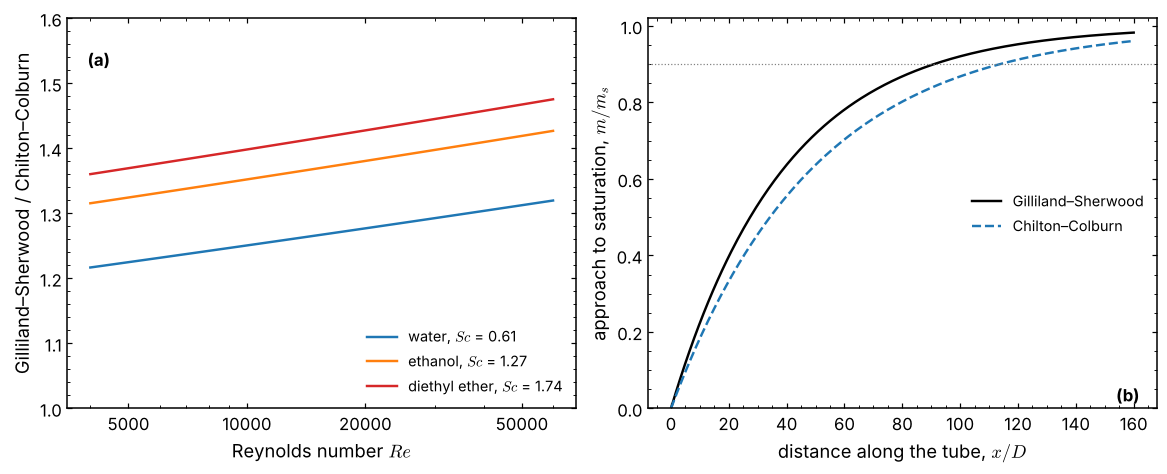

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
Re_g = np.geomspace(4e3, 6e4, 50)
for (name, Dv), color in zip(vapours.items(), ("C0", "C1", "C3")):
    Sc = air["nu"] / Dv
    ax1.plot(Re_g, Sh_gs(Re_g, Sc) / Sh_cc(Re_g, Sc), "-", color=color, label=fr"{name}, $Sc$ = {Sc:.2f}")
ax1.set_xscale("log")
ax1.set_xticks([5e3, 1e4, 2e4, 5e4])
ax1.xaxis.set_major_formatter(plt.ScalarFormatter())
ax1.xaxis.set_minor_formatter(plt.NullFormatter())
ax1.set_xlabel(r"Reynolds number $Re$")
ax1.set_ylabel("Gilliland–Sherwood / Chilton–Colburn")
ax1.set_ylim(1.0, 1.6)
ax1.legend(loc="lower right")
panel_label(ax1, "(a)", x=0.04, y=0.92)

x_d = np.linspace(0, 160, 300)
for (label, Sh), style in ((("Gilliland–Sherwood", Sh_gs(Re, Sc_w)), "k-"), (("Chilton–Colburn", Sh_cc(Re, Sc_w)), "C0--")):
    ax2.plot(x_d, 1 - np.exp(-4 * Sh * x_d / (Re * Sc_w)), style, label=label)
ax2.axhline(0.9, color="0.5", ls=":", lw=0.8)
ax2.set_xlabel(r"distance along the tube, $x/D$")
ax2.set_ylabel(r"approach to saturation, $m/m_s$")
ax2.set_ylim(0, 1.02)
ax2.legend(loc="center right")
panel_label(ax2, "(b)", x=0.92, y=0.06)
plt.show()

**Figure S16.1.** (a) The Gilliland–Sherwood correlation over the Chilton–Colburn analogy
for three vapours in turbulent tube flow. (b) Approach of dry air to saturation with water
along a wetted tube at $Re = 10^4$.

The measured correlation lies 22 to 48 % above the analogy, more for the heavier vapours
and at higher Reynolds numbers. Two things in the experiment favour higher rates: the
column was short (450 mm, 18 diameters), so much of it lay in the entry region where the
concentration layer is thin, and the falling liquid surface is rippled rather than a
smooth wall. The analogy is the safer basis for a long, smooth duct; the correlation for a
column like theirs. Air entering dry reaches 90 % saturation after 2.3 m of tube by
Gilliland and Sherwood and 2.8 m by the analogy, about 90 and 110 diameters: a
wetted-wall humidifier has to be long, because the vapour must cross the whole tube while
the air carries it along.

## Exercise 3. Condensing steam from a mixture

The mixture at 50 % steam by volume has $m_e = 0.38$; at the 40 °C wall the vapour
pressure is 7.4 kPa and $m_s = 0.047$, so $B$ is negative and the flow is towards the wall.

In [5]:
T_w, U, L = 313.15, 2.0, 0.3
gas = properties.dry_air_properties(333.15)          # assumed: air properties at 60 C
D_s = 3.0e-5                                         # assumed diffusivity of steam in air
Sc, Re = gas["nu"] / D_s, U * L / gas["nu"]
m_e = convective_mass.vapour_mass_fraction(0.5 * P_ATM, M_WATER)
m_s = convective_mass.vapour_mass_fraction(properties.saturation_pressure_water(T_w), M_WATER)
B = convective_mass.spalding_number(m_s, m_e)
g_star = gas["rho"] * D_s * convective_mass.sherwood_flat_plate(Re, Sc) / L
ratio = reference.species_similarity(Sc, B)["dphi0"] / reference.species_similarity(Sc)["dphi0"]
cond = {"low rate (16.1)": g_star * (m_e - m_s), "film model (16.7)": -g_star * math.log1p(B),
        "boundary layer (16.8)": -g_star * B * ratio}
print(f"Re = {Re:.3g}, Sc = {Sc:.2f}; m_e = {m_e:.3f}, m_s = {m_s:.4f}, B = {B:.3f}; g/g* exact {ratio:.3f},"
      f" film {convective_mass.film_blowing_factor(B):.3f}")
h_fg = properties.saturated_water(T_w)["h_fg"]
for label, mf in cond.items():
    print(f"{label:22s}: condenses {1e3 * mf:.2f} g/(m2 s), {mf * h_fg / 1e3:.1f} kW/m2")
# pure steam at 1 atm on the same plate held vertical: Nusselt film condensation
wf = properties.water_properties(0.5 * (373.15 + T_w))
h_N = phase_change.h_film_condensation(wf["rho"], 0.6, wf["k"], wf["mu"], properties.saturated_water(373.15)["h_fg"],
                                       373.15 - T_w, L)
q_pure = h_N * (373.15 - T_w)
print(f"pure steam (Nusselt film, 0.3 m vertical plate): h = {h_N:.0f} W/(m2 K), {q_pure / 1e3:.0f} kW/m2,"
      f" {q_pure / (cond['boundary layer (16.8)'] * h_fg):.0f} times the mixture")

Re = 3.16e+04, Sc = 0.63; m_e = 0.383, m_s = 0.0465, B = -0.353; g/g* exact 1.380, film 1.234
low rate (16.1)       : condenses 3.62 g/(m2 s), 8.7 kW/m2
film model (16.7)     : condenses 4.68 g/(m2 s), 11.3 kW/m2
boundary layer (16.8) : condenses 5.24 g/(m2 s), 12.6 kW/m2
pure steam (Nusselt film, 0.3 m vertical plate): h = 5071 W/(m2 K), 304 kW/m2, 24 times the mixture


With $B = -0.35$ the suction thins the vapour layer, and the exact conductance is 1.38
times the low-rate value, against 1.23 by the film model. The plate condenses
5.2 g/(m² s) by the boundary layer (low rate 3.6, film model 4.7), about 12.6 kW/m². Pure
steam on the same plate held vertical, limited only by the liquid film (Chapter 10), gives
about 300 kW/m², 24 times more. The difference is the air. The steam flows to the wall and condenses, but the
air it carries cannot condense, so it piles up at the wall, where its mass fraction rises
from 0.62 in the stream to 0.95. The steam must then diffuse through this air-rich layer,
and diffusion is slow compared with the bulk flow of pure steam. A few per cent of air in
the steam of a power-station condenser ruins its performance, which is why condensers have
air ejectors. The suction itself helps a little: it pulls the stream towards the wall and
thins the layer through which the steam diffuses.

## Exercise 4. What reaches the road

A drop of initial diameter $d_0$ that reaches the road arrives with diameter $d_H$, read
from its fall $z(d)$, and delivers the fraction $(d_H/d_0)^3$ of its water; a drop that
evaporates first delivers nothing. With the mass distributed log-normally in $d_0$ (mass
median $d_m$, geometric standard deviation $\sigma_g$), the delivered fraction is the
average of $(d_H/d_0)^3$ over the normal distribution of $\ln d_0$.

In [6]:
def drop_climate(T_e, RH):
    """Drop temperature from Eq. (16.11) and gas properties at the film temperature (as in Chapter 16)."""
    m_e = convective_mass.vapour_mass_fraction(RH * properties.saturation_pressure_water(T_e), M_WATER)

    def state(T_s):
        T_f = 0.5 * (T_s + T_e)
        a = properties.dry_air_properties(T_f)
        Dv = properties.water_vapour_diffusivity_air(T_f)
        m_s = convective_mass.vapour_mass_fraction(properties.saturation_pressure_water(T_s), M_WATER)
        return a, Dv, convective_mass.spalding_number(m_s, m_e)

    def balance(T_s):
        a, Dv, Bv = state(T_s)
        return a["k"] * (T_e - T_s) - a["rho"] * Dv * math.log1p(Bv) * properties.saturated_water(T_s)["h_fg"]

    T_s = bisect(balance, 274.0, T_e - 1e-6, xtol=1e-9)[0]
    a, Dv, Bv = state(T_s)
    return {"air": a, "D": Dv, "B": Bv, "Sc": a["nu"] / Dv, "rho_l": properties.water_properties(T_s)["rho"]}


H = 3.0
d0_grid = np.geomspace(20e-6, 2e-3, 160)


def arriving_fraction(cl):
    a, out = cl["air"], []
    for d0 in d0_grid:
        r = convective_mass.falling_drop(d0, cl["rho_l"], a["rho"], a["mu"], cl["D"], cl["B"], cl["Sc"], n=2000)
        out.append(0.0 if r["z_life"] <= H else (np.interp(H, r["z"], r["d"]) / d0) ** 3)
    return np.array(out)


def delivered(f_arr, d_m, sigma_g=1.6):
    w = np.exp(-0.5 * (np.log(d0_grid / d_m) / math.log(sigma_g)) ** 2)
    return float(np.sum(w * f_arr) / np.sum(w))


climates = {"summer, 35 C, 20 %": drop_climate(308.15, 0.20), "mild, 20 C, 60 %": drop_climate(293.15, 0.60)}
arr = {label: arriving_fraction(cl) for label, cl in climates.items()}
for label, f_arr in arr.items():
    print(f"{label}: {100 * delivered(f_arr, 120e-6):.1f} % of the water reaches the road (d_m = 120 um);"
          f" a 200 um drop arrives with {100 * np.interp(200e-6, d0_grid, f_arr):.0f} % of its water")
d_m90 = bisect(lambda d: delivered(arr["summer, 35 C, 20 %"], d) - 0.9, 100e-6, 1.2e-3, xtol=1e-8)[0]
print(f"summer: 90 % delivered with a mass median diameter of {1e6 * d_m90:.0f} um")
dm_grid = np.geomspace(60e-6, 800e-6, 40)
deliv = {label: np.array([delivered(f_arr, d) for d in dm_grid]) for label, f_arr in arr.items()}

summer, 35 C, 20 %: 16.3 % of the water reaches the road (d_m = 120 um); a 200 um drop arrives with 59 % of its water
mild, 20 C, 60 %: 40.6 % of the water reaches the road (d_m = 120 um); a 200 um drop arrives with 88 % of its water
summer: 90 % delivered with a mass median diameter of 450 um


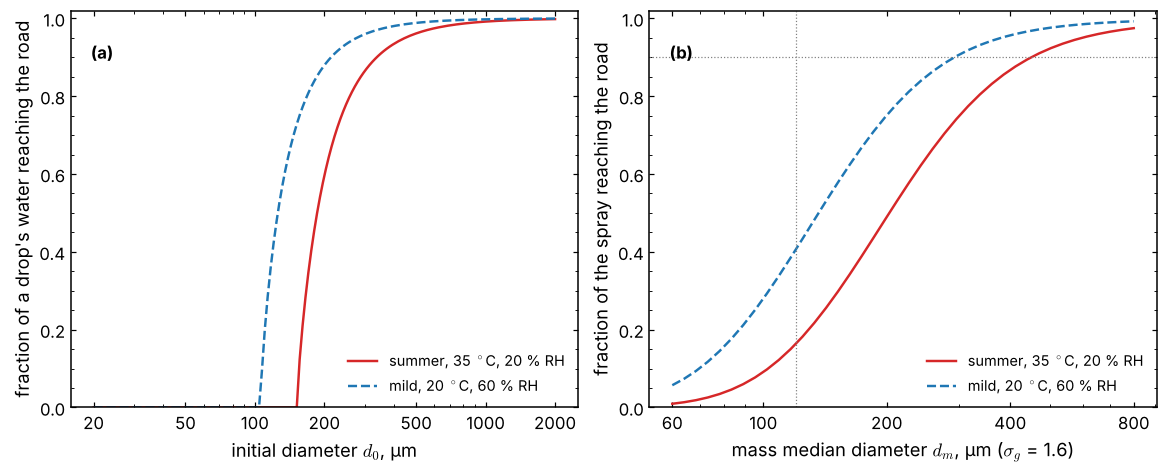

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
for (label, f_arr), style in zip(arr.items(), ("C3-", "C0--")):
    ax1.semilogx(1e6 * d0_grid, f_arr, style, label=label.replace(" C,", r" $^\circ$C,").replace(" %", " % RH"))
    ax2.semilogx(1e6 * dm_grid, deliv[label], style, label=label.replace(" C,", r" $^\circ$C,").replace(" %", " % RH"))
for ax, ticks in ((ax1, [20, 50, 100, 200, 500, 1000, 2000]), (ax2, [60, 100, 200, 400, 800])):
    ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(plt.ScalarFormatter())
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax1.set_xlabel(r"initial diameter $d_0$, μm")
ax1.set_ylabel(r"fraction of a drop's water reaching the road")
ax1.set_ylim(0, 1.02)
ax1.legend(loc="lower right")
panel_label(ax1, "(a)", x=0.04, y=0.92)
ax2.axhline(0.9, color="0.5", ls=":", lw=0.8)
ax2.axvline(120, color="0.5", ls=":", lw=0.8)
ax2.set_xlabel(r"mass median diameter $d_m$, μm ($\sigma_g$ = 1.6)")
ax2.set_ylabel("fraction of the spray reaching the road")
ax2.set_ylim(0, 1.02)
ax2.legend(loc="lower right")
panel_label(ax2, "(b)", x=0.04, y=0.92)
plt.show()

**Figure S16.2.** (a) Fraction of a drop's water that reaches the road 3 m below the
nozzle, against its initial size. (b) Fraction of the whole spray delivered, against the
mass median diameter of a log-normal spray with $\sigma_g = 1.6$; the dotted lines mark
90 % and the nozzle of the exercise.

With a mass median of 120 μm, only 16 % of the water reaches the road in summer and 41 %
on the mild day. The loss is not only the drops that vanish: a 200 μm drop in summer
arrives with 59 % of its water, and only drops of half a millimetre and more arrive nearly
whole. Delivering 90 % in summer needs a mass median of about 450 μm, nearly four times as
coarse, which wets the road but catches fine dust poorly; a dust-suppression spray in hot
dry weather is mostly an evaporative cooler unless its drops are coarse. The
estimate is pessimistic in one way and optimistic in another: a dense spray humidifies and
cools the air it falls through, slowing evaporation, but the drops leave the nozzle faster
than their terminal velocity and are also blown about by wind.